In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [31]:
# Load the dataset
df = pd.read_csv("data/cleaned_turtle_reviews.csv")

## K-Means Clustering

The decision tree model identified `remuneration` and `spending_score` as the key drivers of `loyalty_points`, while `age`, `gender` and `education` contributed little to no predictive value. Therefore, these two features will be used to segment customers with k-means clustering. Before fitting the model, the optimal number of clusters (k) will be determined using the Elbow method and Silhouette score.

In [32]:
# Select and scale the features for clustering
features = ['remuneration', 'spending_score']
scaler = StandardScaler()
X_cluster = scaler.fit_transform(df[features])

### Elbow Method

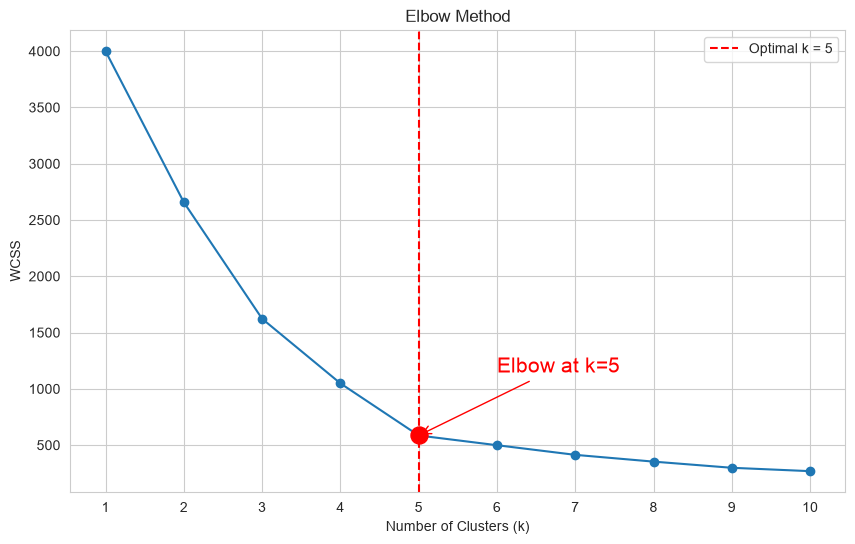

In [37]:
# Calculate WCSS for each k
wcss = []
k_values_elbow = range(1, 11)

for k in k_values_elbow:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_cluster)
    wcss.append(kmeans.inertia_)

# Plot the elbow curve
optimal_k = 5
optimal_wcss = wcss[optimal_k - 1]  # k starts at 1, so index is k-1

sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
plt.plot(k_values_elbow, wcss, marker='o')

# Mark k=5
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k = {optimal_k}')
plt.scatter(optimal_k, optimal_wcss, color='red', s=150, zorder=5)
plt.annotate(f'Elbow at k={optimal_k}',
             xy=(optimal_k, optimal_wcss),
             xytext=(optimal_k + 1, optimal_wcss + (max(wcss) - min(wcss)) * 0.15),
             arrowprops=dict(arrowstyle='->', color='red'),
             color='red', fontsize=15)

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.xticks(k_values_elbow)
plt.legend()
plt.show()

### Silhouette Score

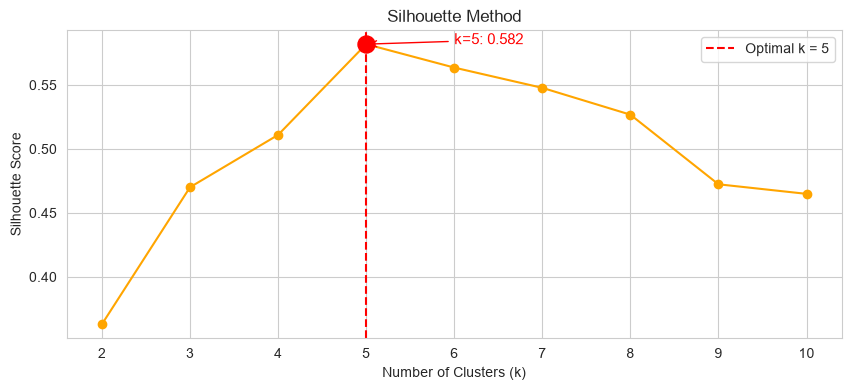

Highest silhouette score: 0.582 at k = 5


In [39]:
# Calculate the silhouette score for each k
silhouette_scores = []
k_values_sil = range(2, 11)

for k in k_values_sil:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_cluster)
    silhouette_scores.append(silhouette_score(X_cluster, labels))

# Plot the silhouette scores
optimal_k = 5
optimal_score = silhouette_scores[optimal_k - 2]  # k starts at 2, so index is k-2

sns.set_style("whitegrid")
plt.figure(figsize=(10, 4))
plt.plot(k_values_sil, silhouette_scores, marker='o', color='orange')

# Mark k=5
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k = {optimal_k}')
plt.scatter(optimal_k, optimal_score, color='red', s=150, zorder=5)
plt.annotate(f'k={optimal_k}: {optimal_score:.3f}',
             xy=(optimal_k, optimal_score),
             xytext=(optimal_k + 1, optimal_score),
             arrowprops=dict(arrowstyle='->', color='red'),
             color='red', fontsize=11)

plt.title('Silhouette Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values_sil)
plt.legend()
plt.show()

# Display the k with the highest silhouette score
best_k = k_values_sil[silhouette_scores.index(max(silhouette_scores))]
print(f"Highest silhouette score: {max(silhouette_scores):.3f} at k = {best_k}")

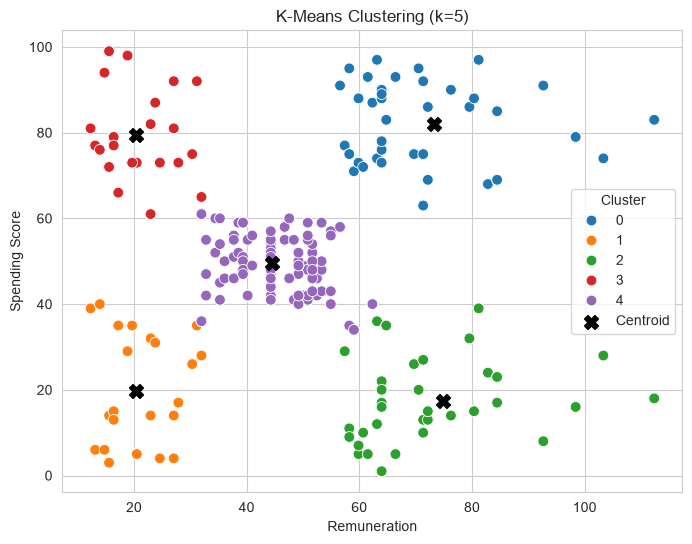

In [29]:
k = 5
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(X_cluster)

# Convert the cluster centres back to the original units for plotting
centres = scaler.inverse_transform(kmeans.cluster_centers_)

# Plot the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='remuneration', y='spending_score',
    hue='cluster',
    palette='tab10',
    s=60
)
plt.scatter(centres[:, 0], centres[:, 1], c='black', marker='X', s=100, label='Centroid')
plt.title(f'K-Means Clustering (k={k})')
plt.xlabel('Remuneration')
plt.ylabel('Spending Score')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()


**Insights from K-Means Clustering (k=5)**

Both the Elbow method and Silhouette score indicate that `k=5` is the optimal number of clusters, revealing five distinct customer segments based on remuneration and spending score.

- **Cluster 0 (Blue): High income, high spending.** 
    - These customers earn and spend the most, and accumulate by far the most loyalty points. They are the most valuable segment and are ideal for premium products, exclusive offers and loyalty rewards that keep them engaged.
- **Cluster 1 (Orange): Low income, low spending.** 
    - These customers earn and spend the least, and hold the fewest loyalty points. They offer limited value per customer, so low-cost incentives such as bonus points on small purchases are more suitable than heavy investment.
- **Cluster 2 (Green): High income, low spending.** 
    - These customers have strong purchasing power but spend relatively little. This makes them the clearest upselling opportunity, for example through personalised recommendations or targeted promotions to raise their spending.
- **Cluster 3 (Red): Low income, high spending.** 
    - These customers spend a lot relative to their income but earn fewer loyalty points than high-income spenders. As they are already highly engaged, retention strategies such as loyalty rewards and member-only discounts can help keep them active.
- **Cluster 4 (Purple): Average income, average spending.** 
    - This is the largest segment and represents the typical Turtle Games customer. General marketing campaigns are best suited to this group, as small improvements in spending across many customers can have a large overall impact.